# Clase 7 — Redes recurrentes: cuando el estado no alcanza

**RL a ciegas · vía profunda (notebooks)**

En la clase 2 vimos el **supuesto de Markov**: si el agente sabe en qué casilla está, el camino que hizo para llegar
no importa. Pero en el modo difícil del juego no ves la casilla: solo sentís cuatro **bigotes** que tocan o no tocan pared.
Ahí la observación no alcanza para decidir y hace falta **memoria**: un resumen del camino.

La idea de esta clase entra en una oración: **la partida es un camino**, igual que una oración es un camino de letras.
Una **red recurrente** (RNN) recorre ese camino de a un paso y lleva un **estado** $h_t$ que lo resume. Con ese estado
un agente se ubica en la cueva, y con el mismo estado un modelo de lenguaje adivina la letra que sigue.

| Paso | Qué hacemos | Qué vamos a ver |
|---|---|---|
| 1 | El caminante al azar: una cadena de Markov | la matriz $P$ y la nube $p_t$ sobre la cueva |
| 2 | Solo bigotes: la observación no es el estado | 12 lecturas para 60 casillas; la memoria achica la nube |
| 3 | El texto como cadena de Markov: n-gramas | generar con n = 2, 4, 8; el error en un texto no visto |
| 4 | La red recurrente | una RNN de letras: lo que espera, su estado, cuánto olvida |
| 5 | De vuelta a la cueva: un agente con memoria | red común contra GRU, y dónde cree la GRU que está |
| 6 | El puente | un modelo de lenguaje es esto, a escala |

Todo corre en CPU en un par de minutos.

## Preparación

La primera celda escribe el entorno `cave_env.py` (el mismo de todas las clases), así el notebook funciona solo en Colab.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 3 (con modelo): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Imports y semillas fijas. Usamos **PyTorch** en CPU (en Colab ya viene instalado).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from cave_env import CaveEnv, ACTION_NAMES

np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(1)      # con redes tan chicas, un hilo es más rápido y el resultado es reproducible
plt.rcParams["figure.dpi"] = 90

### Herramientas

Funciones largas (n-gramas, la red de letras, el agente, los dibujos) y el **corpus**: un diario de la cueva de unas
5.400 letras escrito para este curso. **No hace falta leer esta celda**: en la clase solo usamos sus funciones.
En Colab aparece plegada.

In [3]:
#@title Herramientas (plegable)
# Herramientas: no hace falta leer esto
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from cave_env import CaveEnv, ACTIONS, ACTION_NAMES

AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#2ecc71", "#8d93a3"

# ---------------------------------------------------------------- la cueva grande
CUEVA_GRANDE = [
    "#########################",
    "#S..#.........#.........#",
    "#.#.#####.###.###.#####.#",
    "#...#.....#.........#...#",
    "#.###.#####.###.#.#.#.###",
    "#.#...#.........#...#...#",
    "#.#.#.#.#.###.#.#.#.#.#.#",
    "#.....#...#...#.#...#.#.#",
    "#######.###.###.###.#.#.#",
    "#...#.........#.....#.#.#",
    "#.###.#####.#.#####.#.#.#",
    "#...........#..........G#",
    "#########################",
]


def distancias(env):
    """Pasos mínimos desde cada casilla hasta la salida (búsqueda en anchura)."""
    d = np.full(env.nS, 10**6); d[env.goal] = 0; cola = [env.goal]
    while cola:
        s = cola.pop(0)
        for a in range(4):
            s2, choque = env._move(s, a)
            if not choque and d[s2] == 10**6:
                d[s2] = d[s] + 1; cola.append(s2)
    return d


# ---------------------------------------------------------------- 1. Markov
def matriz_azar(env):
    """P[s, s'] del caminante al azar: cada acción con probabilidad 1/4 (si choca, se queda)."""
    return env.P.mean(axis=1)


def caminante(env, pasos, semilla=0):
    rng = np.random.default_rng(semilla); s = env.start; camino = [s]
    for _ in range(pasos):
        s, _ = env._move(s, int(rng.integers(4))); camino.append(s)
        if s == env.goal: break
    return camino


# ---------------------------------------------------------------- 2. bigotes y creencia
def bigotes(env, s):
    """4 bigotes (↑ → ↓ ←): 1 si hay pared pegada."""
    r, c = env.free[s]
    return tuple(int(env.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values())


def creencia(env, acciones, inicio=None, memoria=True):
    """Casillas compatibles con lo que se sintió. Devuelve (lista de conjuntos, casillas reales).
    memoria=False: solo la lectura de ahora."""
    s = env.start if inicio is None else inicio
    lect = lambda q: bigotes(env, q)
    todas = set(range(env.nS))
    B = {q for q in todas if lect(q) == lect(s)}
    hist, reales = [set(B)], [s]
    for a in acciones:
        s, _ = env._move(s, a)
        compat = {q for q in todas if lect(q) == lect(s)}
        B = ({env._move(q, a)[0] for q in B} & compat) if memoria else compat
        hist.append(set(B)); reales.append(s)
    return hist, reales


# ---------------------------------------------------------------- 3. texto y n-gramas
def preparar_texto(t):
    return " ".join(t.lower().split())


def tabla_ngramas(texto, n):
    """Para cada contexto de n-1 letras, cuántas veces vino cada letra después."""
    tab = {}
    for i in range(len(texto) - n + 1):
        ctx, sig = texto[i:i + n - 1], texto[i + n - 1]
        tab.setdefault(ctx, {}); tab[ctx][sig] = tab[ctx].get(sig, 0) + 1
    return tab


def generar_ngramas(texto, n, largo=300, semilla=0, inicio=None):
    rng = np.random.default_rng(semilla); tab = tabla_ngramas(texto, n)
    out = inicio if inicio is not None else texto[:n - 1]
    while len(out) < largo:
        c = tab.get(out[len(out) - (n - 1):] if n > 1 else "")
        if not c:
            out += " "; continue
        letras, cuentas = zip(*c.items()); p = np.array(cuentas, float); p /= p.sum()
        out += letras[rng.choice(len(letras), p=p)]
    return out


def entropia_ngramas(entren, prueba, n, alfa=0.1, vocab=None):
    """Entropía cruzada (nats por letra) sobre un texto que la tabla no vio, con suavizado de Laplace."""
    vocab = vocab or sorted(set(entren + prueba)); V = len(vocab); tab = tabla_ngramas(entren, n); tot = 0.0
    for i in range(n - 1, len(prueba)):
        c = tab.get(prueba[i - n + 1:i], {}); N = sum(c.values())
        tot -= np.log((c.get(prueba[i], 0) + alfa) / (N + alfa * V))
    return tot / (len(prueba) - n + 1)


def copiado(generado, corpus, k=20):
    """Fracción de los tramos de k letras del texto generado que están literales en el corpus."""
    tramos = {corpus[i:i + k] for i in range(len(corpus) - k + 1)}
    return float(np.mean([generado[i:i + k] in tramos for i in range(len(generado) - k + 1)]))


# ---------------------------------------------------------------- 4. la red recurrente
class ModeloLetras(nn.Module):
    """Modelo de lenguaje de letras. tipo='elman': h_t = tanh(W_hh h_{t-1} + W_xh x_t + b), entrada one-hot.
    tipo='gru': la misma idea con perilla (compuerta)."""
    def __init__(self, vocab, tipo="elman", H=32):
        super().__init__()
        self.vocab, self.tipo, self.H = vocab, tipo, H
        V = len(vocab)
        Celda = nn.RNN if tipo == "elman" else nn.GRU
        self.rnn = Celda(V, H, batch_first=True)
        self.salida = nn.Linear(H, V)

    def forward(self, ids, h=None, devolver_x=False):
        x = nn.functional.one_hot(ids, len(self.vocab)).float()
        if devolver_x: x.requires_grad_(True)
        y, h = self.rnn(x, h)
        return (self.salida(y), h, y, x) if devolver_x else (self.salida(y), h)


def a_ids(texto, vocab):
    i = {c: k for k, c in enumerate(vocab)}
    return torch.tensor([i[c] for c in texto if c in i])


def entropia_red(m, texto):
    ids = a_ids(texto, m.vocab)
    with torch.no_grad():
        lo, _ = m(ids[None, :-1])
    return nn.functional.cross_entropy(lo[0], ids[1:]).item()


def entrenar_lm(texto, vocab, tipo="elman", H=32, pasos=2000, L=48, B=32, lr=3e-3, semilla=0, prueba=None, cada=50):
    """Entrena con trozos de L letras al azar. Si hay texto de prueba, guarda la curva y el mejor modelo."""
    torch.manual_seed(semilla)
    m = ModeloLetras(vocab, tipo, H); opt = torch.optim.Adam(m.parameters(), lr=lr)
    X = a_ids(texto, vocab); hist = {"paso": [], "entren": [], "prueba": []}; mejor = (np.inf, None, 0); acum = []
    for p in range(1, pasos + 1):
        i = torch.randint(0, len(X) - L - 1, (B,))
        xb = torch.stack([X[k:k + L] for k in i]); yb = torch.stack([X[k + 1:k + L + 1] for k in i])
        lo, _ = m(xb); loss = nn.functional.cross_entropy(lo.reshape(-1, len(vocab)), yb.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); acum.append(loss.item())
        if p % cada == 0:
            hist["paso"].append(p); hist["entren"].append(float(np.mean(acum))); acum = []
            if prueba is not None:
                e = entropia_red(m, prueba); hist["prueba"].append(e)
                if e < mejor[0]: mejor = (e, {k: v.clone() for k, v in m.state_dict().items()}, p)
    if prueba is not None:
        m.ultimo_estado = {k: v.clone() for k, v in m.state_dict().items()}
        m.load_state_dict(mejor[1]); m.mejor_paso = mejor[2]
    m.hist = hist
    return m


def generar(m, prefijo, largo=200, temperatura=0.8, semilla=0):
    g = torch.Generator().manual_seed(semilla)
    with torch.no_grad():
        lo, h = m(a_ids(prefijo, m.vocab)[None]); out = prefijo
        for _ in range(largo):
            p = torch.softmax(lo[0, -1] / temperatura, -1); k = torch.multinomial(p, 1, generator=g).item()
            out += m.vocab[k]; lo, h = m(torch.tensor([[k]]), h)
    return out


def estados(m, texto):
    """Estado oculto h_t después de cada letra, y la probabilidad de la letra siguiente."""
    with torch.no_grad():
        x = nn.functional.one_hot(a_ids(texto, m.vocab)[None], len(m.vocab)).float()
        y, _ = m.rnn(x)
        lo = m.salida(y)
    return y[0].numpy(), torch.softmax(lo[0], -1).numpy()


def que_esperaba(m, texto, k=3):
    """Tabla 'qué esperaba en cada paso' (teacher forcing): cada fila es independiente."""
    _, P = estados(m, texto)
    print(f"{'leído hasta acá':>22} | venía | predijo (p)")
    for t in range(len(texto) - 1):
        top = np.argsort(-P[t])[:k]
        cand = "  ".join(f"'{m.vocab[j]}' {P[t, j]:.2f}" for j in top)
        ok = "✓" if m.vocab[top[0]] == texto[t + 1] else " "
        print(f"{texto[max(0, t - 21):t + 1]:>22} |  '{texto[t + 1]}'  | {cand}  {ok}")
    print("Ojo: cada fila se predijo sobre el texto verdadero. La columna 'predijo' NO se lee de corrido.")


def olvido(m, texto):
    """|∂h_T/∂x_i|: cuánto mueve la letra i al estado final. Si cae rápido hacia atrás, la red olvida."""
    ids = a_ids(texto, m.vocab)[None]
    _, _, y, x = m(ids, devolver_x=True)
    y[0, -1].norm().backward()
    return x.grad[0].norm(dim=-1).numpy()


def pca2(H):
    mu = H.mean(0); U, S, Vt = np.linalg.svd(H - mu, full_matrices=False)
    return mu, Vt[:2]


def clase_letra(c):
    if c == " ": return 0
    if c in "aeiouáéíóú": return 1
    if c.isalpha() or c == "ñ": return 2
    return 3


NOMBRES_CLASE = ["espacio", "vocal", "consonante", "signo"]
COLORES_CLASE = ["#5ec8d8", "#f2b35a", "#c58cf2", "#e0645a"]


def dibujar_trayectoria(m, corpus, texto, ax=None, n_fondo=1500):
    """El estado h_t en un plano (PCA). El fondo son estados del corpus pintados según qué letra predicen:
    el plano se lee por lo que predice, no por sus coordenadas."""
    Hc, Pc = estados(m, corpus); mu, W = pca2(Hc)
    idx = np.linspace(0, len(Hc) - 1, min(n_fondo, len(Hc))).astype(int)
    Z = (Hc[idx] - mu) @ W.T; cl = [clase_letra(m.vocab[int(np.argmax(Pc[i]))]) for i in idx]
    if ax is None: _, ax = plt.subplots(figsize=(6.4, 5))
    for k in range(4):
        sel = [j for j, c in enumerate(cl) if c == k]
        ax.scatter(Z[sel, 0], Z[sel, 1], s=7, color=COLORES_CLASE[k], alpha=.35, label=f"predice {NOMBRES_CLASE[k]}")
    Ht, _ = estados(m, texto); Zt = (Ht - mu) @ W.T
    ax.plot(Zt[:, 0], Zt[:, 1], "-", color="k", lw=1.2, alpha=.7)
    for t, c in enumerate(texto):
        ax.annotate("␣" if c == " " else c, Zt[t], fontsize=10, weight="bold", ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="0.4", lw=.5))
    ax.set_xticks([]); ax.set_yticks([]); ax.legend(loc="upper right", fontsize=8, markerscale=2)
    ax.set_title(f"«{texto}»: el estado h_t, letra por letra")
    return ax, (mu, W)


# ---------------------------------------------------------------- 5. el agente con memoria
def obs_agente(env, s, a_prev):
    """Lo que siente el agente: 4 bigotes + la última acción (one-hot; ceros al empezar)."""
    o = np.zeros(8, np.float32); o[:4] = bigotes(env, s)
    if a_prev is not None: o[4 + a_prev] = 1
    return o


def experto(env, dist, s):
    """La acción que acerca a la salida (la conoce quien ve el mapa)."""
    return int(np.argmin([dist[env._move(s, a)[0]] if not env._move(s, a)[1] else 10**7 for a in range(4)]))


def datos_imitacion(env, dist, episodios=2000, T=60, eps=0.3, semilla=1):
    """Partidas desde casillas al azar. Se juega como el experto, pero con prob. eps una acción al azar
    (así aparecen situaciones fuera del camino ideal). La etiqueta es siempre la acción del experto."""
    rng = np.random.default_rng(semilla); inicios = [s for s in range(env.nS) if s != env.goal]
    X, Y, S, M = [], [], [], []
    for _ in range(episodios):
        s = inicios[rng.integers(len(inicios))]; ap = None; xs, ys, ss = [], [], []
        for t in range(T):
            xs.append(obs_agente(env, s, ap)); ys.append(experto(env, dist, s)); ss.append(s)
            a = int(rng.integers(4)) if rng.random() < eps else experto(env, dist, s)
            s, _ = env._move(s, a); ap = a
            if s == env.goal: break
        L = len(xs); pad = T - L
        X.append(np.pad(np.array(xs), ((0, pad), (0, 0)))); Y.append(ys + [0] * pad); S.append(ss + [0] * pad); M.append([1] * L + [0] * pad)
    return torch.tensor(np.array(X)), torch.tensor(Y), torch.tensor(S), torch.tensor(M, dtype=torch.float32)


class SinMemoria(nn.Module):
    """Red común (MLP): decide solo con lo que siente ahora."""
    def __init__(self, H=32):
        super().__init__(); self.f = nn.Sequential(nn.Linear(8, H), nn.Tanh(), nn.Linear(H, H), nn.Tanh(), nn.Linear(H, 4))
    def forward(self, x, h=None):
        return self.f(x), None


class ConMemoria(nn.Module):
    """Red recurrente (GRU): decide con lo que siente ahora y con su estado h_t."""
    def __init__(self, H=32):
        super().__init__(); self.gru = nn.GRU(8, H, batch_first=True); self.salida = nn.Linear(H, 4)
    def forward(self, x, h=None):
        y, h = self.gru(x, h); self.y = y
        return self.salida(y), h


def entrenar_imitacion(m, datos, pasos=800, B=64, lr=3e-3, semilla=0):
    torch.manual_seed(semilla); X, Y, S, M = datos; opt = torch.optim.Adam(m.parameters(), lr=lr); hist = []
    for _ in range(pasos):
        i = torch.randint(0, len(X), (B,)); lo, _ = m(X[i])
        l = (nn.functional.cross_entropy(lo.reshape(-1, 4), Y[i].reshape(-1), reduction="none") * M[i].reshape(-1)).sum() / M[i].sum()
        opt.zero_grad(); l.backward(); opt.step(); hist.append(l.item())
    return hist


def jugar(m, env, inicio, T=200):
    """Juega con la acción más probable. Devuelve el camino y los estados h_t (si tiene memoria)."""
    s, ap, h, camino, hs = inicio, None, None, [inicio], []
    with torch.no_grad():
        for _ in range(T):
            lo, h = m(torch.tensor(obs_agente(env, s, ap))[None, None], h)
            if h is not None: hs.append(h[0, 0].numpy().copy())
            a = int(lo[0, 0].argmax()); s, _ = env._move(s, a); ap = a; camino.append(s)
            if s == env.goal: break
    return camino, hs


def evaluar(m, env, dist, T=200):
    inicios = [s for s in range(env.nS) if s != env.goal]; ok, extra, atascadas = 0, [], []
    for s0 in inicios:
        c, _ = jugar(m, env, s0, T)
        if c[-1] == env.goal: ok += 1; extra.append(len(c) - 1 - dist[s0])
        else: atascadas.append(s0)
    return {"exito": ok / len(inicios), "pasos_de_mas": float(np.mean(extra)), "atascadas": atascadas, "n": len(inicios)}


def entrenar_sonda(m, datos, env, pasos=600, lr=1e-2, semilla=0):
    """Sonda lineal: desde h_t, adivinar en qué casilla está. Es la forma de 'ver' el estado:
    no se dibuja h_t, se dibuja lo que cree sobre la cueva."""
    torch.manual_seed(semilla); X, Y, S, M = datos
    with torch.no_grad():
        m(X); Hs = m.y
    sonda = nn.Linear(Hs.shape[-1], env.nS); opt = torch.optim.Adam(sonda.parameters(), lr=lr)
    Hf, Sf, Mf = Hs.reshape(-1, Hs.shape[-1]), S.reshape(-1), M.reshape(-1) > 0
    Hf, Sf = Hf[Mf], Sf[Mf]
    for _ in range(pasos):
        i = torch.randint(0, len(Hf), (2048,)); l = nn.functional.cross_entropy(sonda(Hf[i]), Sf[i])
        opt.zero_grad(); l.backward(); opt.step()
    return sonda


def plot_curva(ax, ys, color, label, suave=25):
    ys = np.asarray(ys, float); k = max(1, min(suave, len(ys) // 5))
    ax.plot(np.convolve(ys, np.ones(k) / k, mode="valid"), color=color, label=label)

# ---------------------------------------------------------------- el corpus (texto propio del curso)
CORPUS = preparar_texto("""
diario de la cueva a ciegas. entro a la cueva y no veo nada. toco la pared con la mano (la pared está fría) y doy un paso a la derecha. no hay pared a la derecha. doy otro paso a la derecha. toco la pared de arriba y la pared de abajo: estoy en un pasillo. un pasillo se siente igual en toda la cueva (arriba pared, abajo pared) y por eso no sé dónde estoy. si solo miro lo que toco ahora, me pierdo. si me acuerdo de lo que toqué antes, me ubico.
la salida es un cuadrado verde. no la veo, pero sé que está. cuando llego, la cueva me paga un punto. cuando no llego, la cueva no dice nada. camino a la derecha, camino abajo, choco con la pared (otra vez la pared) y vuelvo arriba. la pared no me dice dónde estoy: me dice que por ahí no se pasa.
anoto todo en el cuaderno. paso uno: derecha. paso dos: derecha. paso tres: pared. paso cuatro: abajo. el cuaderno es mi memoria. sin el cuaderno, cada paso es el primero. con el cuaderno, cada paso tiene un pasado. el pasado no se ve, pero se nota en lo que hago.
el caminante sin memoria camina al azar. tira una moneda de cuatro caras y da un paso: arriba, derecha, abajo o izquierda. si choca, se queda donde está. a dónde va después depende solo de dónde está ahora (no de dónde estuvo). eso es una cadena de markov. el caminante no aprende nada: vuelve a chocar con la misma pared una y otra vez, y llega a la salida de casualidad.
el que juega con memoria no camina al azar. se acuerda de la pared de la izquierda y no vuelve a tocarla. se acuerda del pasillo largo (el que bajaba hacia el sur) y sabe que al final hay una esquina. se acuerda de cuántos pasos dio desde la esquina y adivina en qué casilla está. la memoria no es el mapa: es un resumen del camino.
tengo cuatro bigotes, como un gato. el bigote de arriba toca o no toca. el de la derecha toca o no toca. el de abajo y el de la izquierda, igual. con cuatro bigotes hay dieciséis lecturas posibles, pero en la cueva hay sesenta casillas. muchas casillas se sienten igual. en algunas conviene subir y en otras conviene bajar. la lectura sola no alcanza para decidir (la lectura es la observación, no el estado).
para saber dónde estoy junto lo que toco ahora con lo que me acuerdo. si en el paso anterior estaba en un pasillo y doblé a la derecha, y ahora toco pared arriba y pared a la derecha, entonces estoy en una esquina. no en cualquier esquina: en la esquina que viene después de ese pasillo. el camino me ubica. una casilla sola no me ubica.
la memoria también se equivoca. si me acuerdo mal de un paso (si creo que doblé a la izquierda cuando doblé a la derecha), el resumen queda torcido y me pierdo igual. por eso la memoria tiene que ser corta y buena: guardar lo que sirve para decidir y olvidar el resto.
una red que lee de a una letra hace lo mismo que el que juega con memoria. lee una letra, la junta con lo que traía, y guarda un estado nuevo. el estado es un resumen de todo lo que leyó. con ese estado adivina la letra que viene. si leyó "la pa", adivina que viene una "r" (la pared) o una "s" (el paso). si leyó "la sa", adivina "l" (la salida).
la red no ve el texto entero. ve una letra por vez, igual que yo veo una casilla por vez. lo que leyó antes está en el estado, como lo que caminé antes está en el cuaderno. la regla para mezclar la letra nueva con el estado viejo es siempre la misma (la misma tabla de pesos en cada paso). lo que cambia es el estado.
contar no alcanza. si cuento qué letra viene después de las dos últimas letras, aprendo palabras cortas, pero no aprendo a cerrar un paréntesis que abrí hace veinte letras (el paréntesis quedó lejos). para cerrarlo hay que acordarse de que estaba abierto. el que cuenta se olvida; el que lleva un estado, no.
salgo de la cueva. afuera hay luz y veo todo el mapa: ahora es fácil. pero adentro no había mapa, había paredes y un cuaderno. aprendí a salir con lo que toqué y con lo que me acordé. la próxima vez que entre a una cueva a ciegas voy a llevar el cuaderno (y una buena memoria).
segundo día en la cueva. entro otra vez y el cuaderno está en blanco. doy un paso abajo. toco la pared de la izquierda. doy otro paso abajo. toco la pared de la izquierda y la pared de la derecha: estoy en un pasillo que baja. sigo bajando hasta que choco (la pared de abajo) y doblo a la derecha. ahora el pasillo va hacia el este. cuento los pasos: uno, dos, tres, cuatro, cinco. al quinto paso no hay pared arriba. subo.
el que cuenta pasos sabe más que el que solo toca. el que solo toca está siempre en el primer paso. el que cuenta pasos sabe cuánto camino hizo desde la última esquina, y eso alcanza para ubicarse (casi siempre). un número chico en la cabeza vale más que una lectura grande en la mano.
la cueva es un juego, pero el problema es de todos los días. un médico no ve la enfermedad: ve síntomas, y se acuerda de la historia del paciente. un traductor no ve el sentido de la frase: ve palabras de a una, y se acuerda de las que ya leyó. un robot no ve la habitación entera: ve lo que le muestra su sensor, y se acuerda de por dónde pasó. en todos los casos la observación no es el estado, y hace falta memoria.
último día en la cueva. ya no anoto todo: anoto lo que sirve. la pared de la izquierda, el pasillo que baja, la esquina del este. con eso alcanza. salgo en veinte pasos (sin chocar ni una vez) y la cueva me paga su punto. la memoria buena no es la que guarda todo: es la que guarda lo justo para decidir.
""")
VOCAB = sorted(set(CORPUS))
print(f"corpus: {len(CORPUS)} letras, {len(VOCAB)} símbolos distintos")

corpus: 5420 letras, 38 símbolos distintos


## Paso 1 — El caminante sin memoria

Un caminante tira un dado de cuatro caras en cada paso; si choca contra una pared, se queda donde está.
Adónde va **depende solo de dónde está ahora**. Eso es una **cadena de Markov** (*Markov chain*).

Todo lo que hace el caminante entra en una tabla: la **matriz de transición** $P$, de 60 × 60 (una fila por casilla de
partida, una columna por casilla de llegada). Vamos a ver la tabla como imagen y, al lado, una caminata de 60 pasos.

cada fila suma 1: True


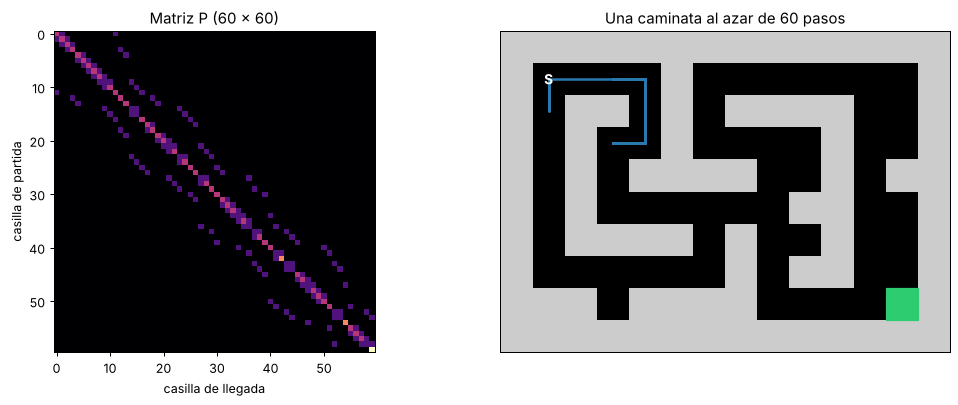

In [4]:
env = CaveEnv()
P = matriz_azar(env)                      # P[s, s'] = probabilidad de pasar de s a s'
print("cada fila suma 1:", np.allclose(P.sum(1), 1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].imshow(P, cmap="magma"); ax[0].set_title("Matriz P (60 × 60)")
ax[0].set_xlabel("casilla de llegada"); ax[0].set_ylabel("casilla de partida")
env.plot(path=caminante(env, 60, semilla=3), ax=ax[1], title="Una caminata al azar de 60 pasos")
plt.tight_layout(); plt.show()

Casi toda la tabla es cero: desde una casilla solo se llega a sus vecinas o a ella misma (la diagonal es *chocar*).
La caminata vuelve una y otra vez sobre sus pasos: **no recuerda nada**.

Si en vez de un caminante pensamos en la **nube** de todos los caminantes posibles, la probabilidad $p_t$ de estar en cada
casilla se actualiza multiplicando por la tabla:

$$p_{t+1} = p_t \, P$$

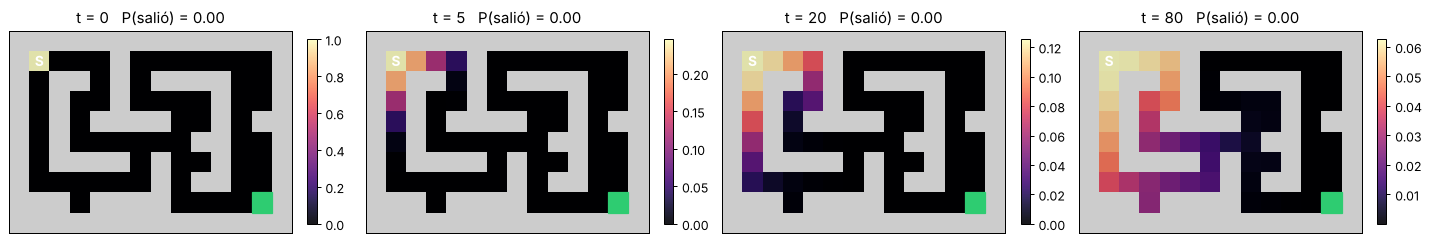

In [5]:
p = np.zeros(env.nS); p[env.start] = 1.0
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
t = 0
for k, hasta in enumerate([0, 5, 20, 80]):
    while t < hasta:
        p = p @ P; t += 1
    env.plot(values=p, ax=ax[k], title=f"t = {t}   P(salió) = {p[env.goal]:.2f}")
plt.tight_layout(); plt.show()

La nube se desparrama por la cueva y, muy de a poco, se junta en la salida (que es absorbente: el que llega, se queda).

> ✍️ **Ejercicio:** cambiá `80` por `400`. ¿Cuánto tarda la mitad de la nube en salir? Compará con los 20 pasos del camino
> más corto.

## Paso 2 — Solo bigotes: la observación no es el estado

Ahora el agente no sabe su casilla: solo siente los cuatro bigotes (↑ → ↓ ←). Pintemos cada casilla según lo que se siente
en ella: casillas del mismo color **se sienten igual**.

60 casillas, 12 lecturas distintas


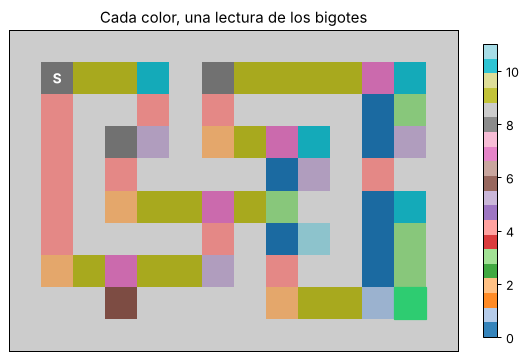

In [6]:
lecturas = sorted({bigotes(env, s) for s in range(env.nS)})
ident = [lecturas.index(bigotes(env, s)) for s in range(env.nS)]
print(f"{env.nS} casillas, {len(lecturas)} lecturas distintas")
env.plot(values=ident, cmap="tab20", title="Cada color, una lectura de los bigotes")
plt.show()

Doce lecturas para sesenta casillas. Un pasillo vertical se siente igual en toda la cueva, pero en unos conviene subir y en
otros bajar: la lectura sola **no es Markov**. Esto es un **MDP parcialmente observable** (*POMDP*).

¿Qué alcanza, entonces? **La historia**. Si me acuerdo de lo que sentí y de lo que hice, puedo descartar casillas:
me quedo con las que, movidas con mi acción, dan la lectura nueva. Ese conjunto es un **estado de creencia** (*belief state*):

$$b_{t+1} = \{\, \text{mover}(s, a_t) : s \in b_t \,\} \;\cap\; \{\, s' : \text{bigotes}(s') = o_{t+1} \,\}$$

Arrancamos en la casilla (8, 10) sin saberlo, y caminamos ← ← ↑ ↑.

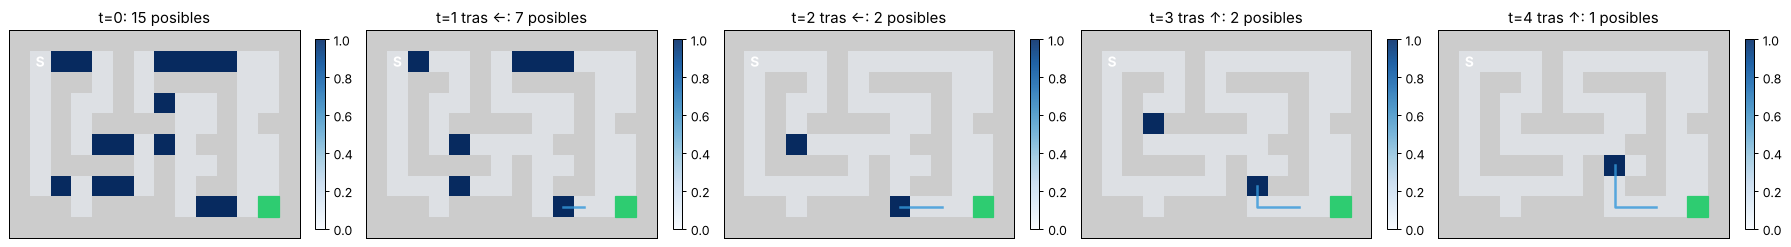

In [7]:
inicio = env.pos2s[(8, 10)]
acciones = [3, 3, 0, 0]
hist, reales = creencia(env, acciones, inicio=inicio)
fig, ax = plt.subplots(1, len(hist), figsize=(4 * len(hist), 3.4))
for t, (B, s) in enumerate(zip(hist, reales)):
    v = np.zeros(env.nS); v[list(B)] = 1
    env.plot(values=v, ax=ax[t], path=reales[:t + 1], cmap="Blues",
             title=f"t={t}" + (f" tras {ACTION_NAMES[acciones[t-1]]}" if t else "") + f": {len(B)} posibles")
plt.tight_layout(); plt.show()

En cuatro pasos la nube pasa de 15 casillas a una sola: **el camino ubica; una casilla sola no**.

¿Es un caso de suerte? Midámoslo: 200 caminatas al azar de 30 pasos, desde casillas al azar, contando cuántas casillas
quedan posibles **sin memoria** (solo la lectura de ahora) y **con memoria** (toda la historia).

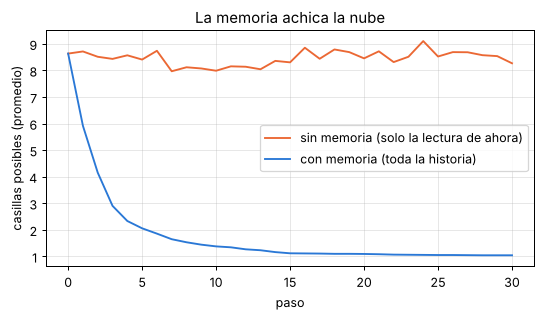

después de 30 pasos: sin memoria 8.3 casillas posibles, con memoria 1.04


In [8]:
rng = np.random.default_rng(0)
sin_m, con_m = [], []
for _ in range(200):
    s0 = int(rng.integers(env.nS))
    acc = list(rng.integers(0, 4, 30))
    sin_m.append([len(b) for b in creencia(env, acc, inicio=s0, memoria=False)[0]])
    con_m.append([len(b) for b in creencia(env, acc, inicio=s0, memoria=True)[0]])
plt.figure(figsize=(7, 3.4))
plt.plot(np.mean(sin_m, 0), color=NARANJA, label="sin memoria (solo la lectura de ahora)")
plt.plot(np.mean(con_m, 0), color=AZUL, label="con memoria (toda la historia)")
plt.xlabel("paso"); plt.ylabel("casillas posibles (promedio)"); plt.legend(); plt.grid(alpha=.3)
plt.title("La memoria achica la nube"); plt.show()
print(f"después de 30 pasos: sin memoria {np.mean(sin_m, 0)[-1]:.1f} casillas posibles, con memoria {np.mean(con_m, 0)[-1]:.2f}")

El agente que tiene que decidir con bigotes necesita **algo que haga este trabajo**: un resumen de la historia que alcance
para ubicarse. Acá lo calculamos a mano porque conocemos el mapa. Sin mapa, ese resumen hay que **aprenderlo**:
eso es lo que va a hacer la red recurrente. Antes, un desvío por el texto, donde la historia es todavía más evidente.

## Paso 3 — El texto como cadena de Markov: n-gramas

Un texto también es un camino: una letra detrás de otra. La forma más vieja de predecir la letra que viene es **contar**:
para cada grupo de $n-1$ letras, cuántas veces vino cada letra después. Eso es un **n-grama** (*n-gram*), y es una cadena
de Markov cuyo estado son las últimas $n-1$ letras:

$$P(x_t \mid \text{contexto}) = \frac{\text{cuenta}(\text{contexto} + x_t)}{\text{cuenta}(\text{contexto})}$$

Primero miremos la tabla para dos contextos.

In [9]:
print(CORPUS[:300], "...\n")
for n, ctx in [(3, "pa"), (4, "la ")]:
    tab = tabla_ngramas(CORPUS, n)
    total = sum(tab[ctx].values())
    top = sorted(tab[ctx].items(), key=lambda kv: -kv[1])[:5]
    print(f"n={n}: después de «{ctx}» →", "  ".join(f"'{c}' {v/total:.2f}" for c, v in top))

diario de la cueva a ciegas. entro a la cueva y no veo nada. toco la pared con la mano (la pared está fría) y doy un paso a la derecha. no hay pared a la derecha. doy otro paso a la derecha. toco la pared de arriba y la pared de abajo: estoy en un pasillo. un pasillo se siente igual en toda la cueva ...

n=3: después de «pa» → 's' 0.45  'r' 0.43  'g' 0.03  ':' 0.03  'l' 0.03
n=4: después de «la » → 'p' 0.21  'c' 0.14  'd' 0.13  'm' 0.11  'i' 0.07


Ahora generamos 300 letras tirando el dado con esas cuentas, para tres valores de n. Medimos cuánto del texto generado está **copiado tal cual** del corpus (tramos de 20 letras).

In [10]:
for n in [2, 4, 8]:
    g = generar_ngramas(CORPUS, n, largo=300, semilla=1)
    print(f"--- n = {n}  ({len(tabla_ngramas(CORPUS, n))} contextos, copiado {100*copiado(g, CORPUS):.0f} %)")
    print(g, "\n")

--- n = 2  (38 contextos, copiado 0 %)
damamigo ntireci lla mi rteso bies tar e punor y lerdecuelelo d mo cho) ell d quinorez ha a. e co pan el uesoba dera en es mena cilasquén qunto lorer lé alano ca ber a qu (l enar bay care: sajueri ede vecho. abartán tro. lcunte la lo qués quente ciod trra e dena, do léno ego dó. lo pardos parivemint 

--- n = 4  (1084 contextos, copiado 0 %)
diarior ahora es el primer paso lo que toco estado, no (y una estado ve si letraía, adivina de arriba en cuaderno. la cuerda, igual azar. la izquierde. no hizo después del ten la cinco. ante paso con la desde es mismo la izquinal azar. lo que estado donde cueva memoria. siene sirve es el es lectura  

--- n = 8  (3882 contextos, copiado 36 %)
diario de la derecha toca o no toca. el que cuenta pasos sabe más que una lectura sola no alcanza. si choca, se queda donde está ahora con lo que sirve. la pared de abajo) y doblé a la izquierda. doy otro paso abajo. el camino abajo. el camino hizo desde la esquina. se ac

Con n chico inventa palabras; con n grande **copia** el corpus. Para medirlo bien separamos el corpus: entrenamos la tabla con
la primera parte (hasta "segundo día") y medimos el error sobre la parte que no vio. El error es la **entropía cruzada**
(*cross-entropy*) en nats por letra: cuanto más baja, mejor predice.

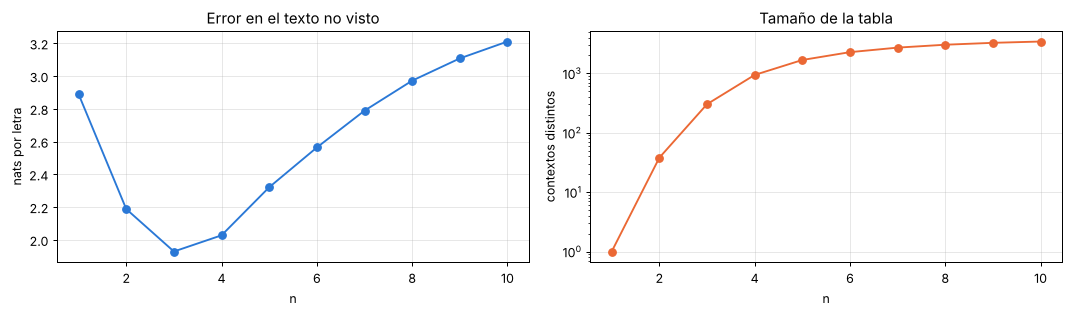

mejor n = 3: 1.93 nats por letra


In [11]:
corte = CORPUS.index("segundo día")
ENT, PRU = CORPUS[:corte], CORPUS[corte:]
ns = list(range(1, 11))
err = [entropia_ngramas(ENT, PRU, n, alfa=0.1, vocab=VOCAB) for n in ns]
ctx = [len(tabla_ngramas(ENT, n)) for n in ns]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(ns, err, "o-", color=AZUL); ax[0].set_xlabel("n"); ax[0].set_ylabel("nats por letra")
ax[0].set_title("Error en el texto no visto"); ax[0].grid(alpha=.3)
ax[1].semilogy(ns, ctx, "o-", color=NARANJA); ax[1].set_xlabel("n"); ax[1].set_ylabel("contextos distintos")
ax[1].set_title("Tamaño de la tabla"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
MEJOR_N = ns[int(np.argmin(err))]
print(f"mejor n = {MEJOR_N}: {min(err):.2f} nats por letra")

El error baja hasta $n = 3$ y después **sube**: con contextos largos, casi cada contexto se vio una sola vez y la tabla no
sabe qué hacer con uno nuevo. Y aunque tuviéramos texto de sobra, un n-grama **nunca recuerda más de $n-1$ letras**:
para cerrar un paréntesis abierto hace veinte letras haría falta una tabla con un renglón por cada cadena de veinte letras.

**Contar no alcanza.** Hace falta algo que guarde lo importante del pasado en un tamaño fijo.

## Paso 4 — La red recurrente

La solución es una flecha. Una red lee una letra $x_t$ por vez y, además de la letra, recibe **lo que dejó el paso anterior**:
un vector $h_{t-1}$, el **estado oculto**. Lo mezcla con la letra nueva y devuelve el estado nuevo:

$$h_t = \tanh(W_{hh}\, h_{t-1} + W_{xh}\, x_t + b) \qquad \hat y_t = \text{softmax}(W_{hy}\, h_t)$$

Las tablas $W$ **son las mismas en todos los pasos**: la red no crece con el texto. La regla no cambia; el estado sí.
Esto es la red recurrente simple de Elman (1990). Usamos un estado de 32 números y la letra entra como *one-hot*.
Es **la misma red que corre en la página de la clase**, con las mismas semillas.

3558 pesos, entrenada en 17 s


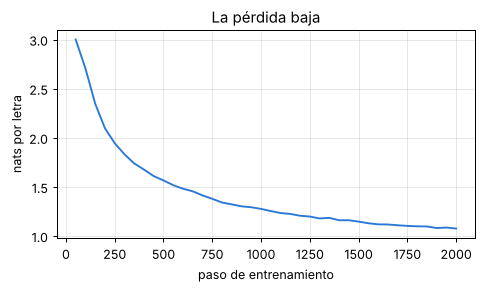

In [12]:
t0 = time.time()
elman = entrenar_lm(CORPUS, VOCAB, "elman", H=32, pasos=2000, semilla=0)
n_pesos = sum(p.numel() for p in elman.parameters())
print(f"{n_pesos} pesos, entrenada en {time.time() - t0:.0f} s")
plt.figure(figsize=(6, 3)); plt.plot(elman.hist["paso"], elman.hist["entren"], color=AZUL)
plt.xlabel("paso de entrenamiento"); plt.ylabel("nats por letra"); plt.title("La pérdida baja"); plt.grid(alpha=.3); plt.show()

Ahora la dejamos escribir sola: cada letra que elige se vuelve la entrada del paso siguiente. La **temperatura** controla cuánto se arriesga (baja: repite lo más probable; alta: inventa).

In [13]:
for T in [0.3, 0.7, 1.2]:
    print(f"--- temperatura {T}")
    print(generar(elman, "la pared ", largo=200, temperatura=T, semilla=2), "\n")

--- temperatura 0.3


la pared de la izquierda de derecha, y se acuerda de la pared de la erna. siempre al estoria es una esquina. si me acuerda de la está en el cuaderno. se ubica. la pared de la er aridó de estaba pared de la ern 

--- temperatura 0.7
la pared con el cuatoro el que serestado que dico aduell para si vemoria pared) y alcilver astába. se acuerda de la cuevo. se actiba se liegua está. mán un pasillo. el pasado derel anota no ao dónde es estoy e 

--- temperatura 1.2
la pared ciaderno tadido). la reguardo no abisiesé, ley ubía esil fría, caminor (salgo, putra priprso josto y poro la merdo, ceréctiva esquivla hasfino. uenta cuadorn cornadía en la nóna. si o dubla biadurno.  



### Qué esperaba en cada paso

Para ver el estado sin dibujarlo, le preguntamos en cada posición **qué cree que viene**. Ojo con cómo se pregunta: le damos
el texto **verdadero** y en cada posición predice la letra siguiente (*teacher forcing*, igual que al entrenar). Cada fila
es una pregunta distinta sobre el texto real, así que **la columna "predijo" no se lee de corrido**: no es un texto.

In [14]:
que_esperaba(elman, "toco la pared (la de la")

       leído hasta acá | venía | predijo (p)
                     t |  'o'  | 'o' 0.58  'r' 0.34  'a' 0.06  ✓
                    to |  'c'  | 'd' 0.46  's' 0.17  'c' 0.13   
                   toc |  'o'  | 'o' 0.66  'a' 0.30  'i' 0.03  ✓
                  toco |  ' '  | '.' 0.53  ' ' 0.29  ',' 0.04   
                 toco  |  'l'  | 'a' 0.59  'o' 0.14  'd' 0.08   
                toco l |  'a'  | 'a' 0.82  'e' 0.08  'o' 0.06  ✓
               toco la |  ' '  | ' ' 0.99  's' 0.00  'y' 0.00  ✓
              toco la  |  'p'  | 'p' 0.26  'c' 0.22  'm' 0.15  ✓
             toco la p |  'a'  | 'a' 0.89  'r' 0.03  'e' 0.03  ✓
            toco la pa |  'r'  | 'r' 0.90  's' 0.06  'l' 0.02  ✓
           toco la par |  'e'  | 'e' 0.86  'a' 0.04  'n' 0.02  ✓
          toco la pare |  'd'  | 'd' 0.95  'c' 0.02  'b' 0.01  ✓
         toco la pared |  ' '  | ' ' 0.61  ')' 0.21  ',' 0.07  ✓
        toco la pared  |  '('  | 'd' 0.49  'c' 0.18  'a' 0.09   
       toco la pared ( |  'l'  | 's' 0.49  'e

Acierta donde hay pocas opciones (después de «pa» viene «r» o «s») y duda donde puede venir cualquier palabra. Que acierte
poco después de un espacio no es una falla del modelo: es la tarea.

### El estado, letra por letra

El estado son 32 números. Los dibujamos como un mapa de calor: una columna por letra leída, una fila por dimensión.

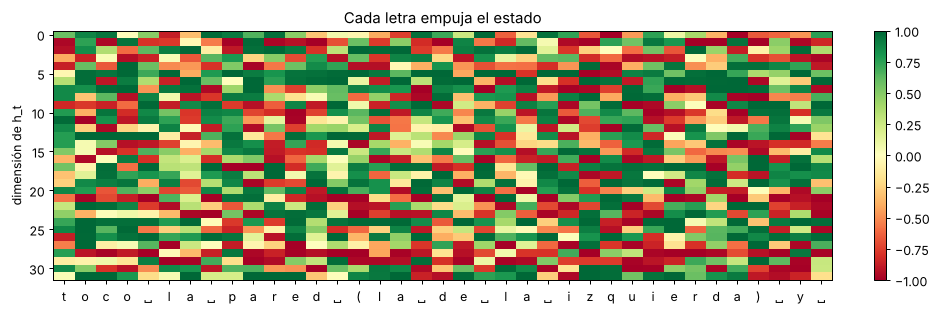

In [15]:
frase = "toco la pared (la de la izquierda) y "
Hs, _ = estados(elman, frase)
plt.figure(figsize=(12, 3.6))
plt.imshow(Hs.T, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(len(frase)), ["␣" if c == " " else c for c in frase])
plt.ylabel("dimensión de h_t"); plt.colorbar(fraction=.02); plt.title("Cada letra empuja el estado")
plt.show()

Hay dimensiones que cambian con cada letra y otras que se mueven poco. Pero los números del estado **no tienen letras**:
leer la dimensión 17 no dice nada. Para dibujar el estado como un camino lo proyectamos a un plano (PCA) y pintamos el
fondo con estados del corpus **según qué letra predicen**: así el plano se lee por lo que hace.

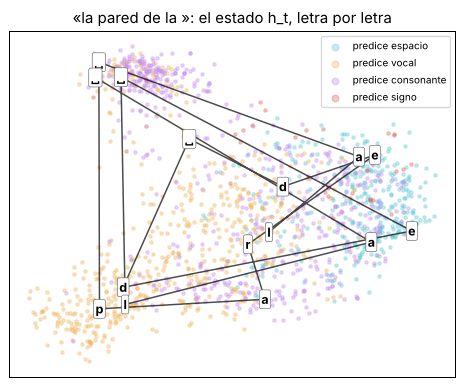

In [16]:
dibujar_trayectoria(elman, CORPUS, "la pared de la ")
plt.show()

Cada letra mueve el punto; después de un espacio el estado cae en la zona que predice consonante, después de una
consonante en la que predice vocal. **El estado es un sistema dinámico** y las letras son las fuerzas que lo empujan.

### El olvido, medido con un gradiente

¿Cuánto mueve una letra vieja al estado final? Lo medimos con el gradiente $|\partial h_T / \partial x_i|$, primero en la
red **sin entrenar** (pesos al azar) y después en la entrenada.

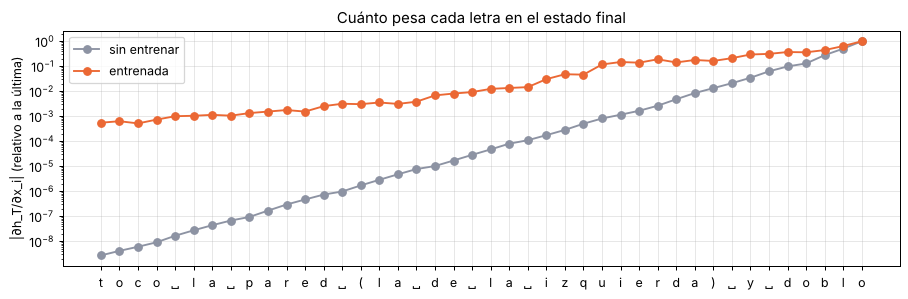

la primera letra pesa 2.7e-09 de la última sin entrenar, y 5.5e-04 entrenada


In [17]:
torch.manual_seed(1)
sin_entrenar = ModeloLetras(VOCAB, "elman", H=32)
frase = "toco la pared (la de la izquierda) y doblo"
g0, g1 = olvido(sin_entrenar, frase), olvido(elman, frase)
plt.figure(figsize=(12, 3.4))
plt.semilogy(g0 / g0[-1], "o-", color=GRIS, label="sin entrenar")
plt.semilogy(g1 / g1[-1], "o-", color=NARANJA, label="entrenada")
plt.xticks(range(len(frase)), ["␣" if c == " " else c for c in frase])
plt.ylabel("|∂h_T/∂x_i| (relativo a la última)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Cuánto pesa cada letra en el estado final"); plt.show()
print(f"la primera letra pesa {g0[0]/g0[-1]:.1e} de la última sin entrenar, y {g1[0]/g1[-1]:.1e} entrenada")

Sin entrenar, el efecto de una letra **cae geométricamente** hacia atrás: cada paso lo multiplica por un número menor que uno.
Eso es el **gradiente que se desvanece** (*vanishing gradient*), y es la razón por la que una RNN simple aprende mal lo que
pasó lejos. Entrenar la ayuda, pero no del todo.

### La perilla: GRU (y LSTM)

La **GRU** (Cho et al., 2014) le agrega a la red una **perilla** $z_t$, un número entre 0 y 1 por dimensión, que decide
cuánto conservar del estado viejo y cuánto renovar:

$$h_t = (1 - z_t)\, h_{t-1} + z_t\, \tilde h_t$$

Es un **promedio ponderado entre quedarse y moverse**: con $z \approx 0$ la dimensión casi no se toca y guarda memoria larga.
(PyTorch escribe la misma ecuación con $z$ del otro lado: en su convención $z$ pondera el estado viejo.)
La **LSTM** (Hochreiter y Schmidhuber, 1997) es la versión anterior, con tres perillas y dos estados; hace lo mismo.

Entrenamos una GRU de 64 estados con la misma división que los n-gramas, mirando el error en el texto no visto cada 50 pasos.

entrenada en 17 s; mejor error en texto no visto 1.76 en el paso 350


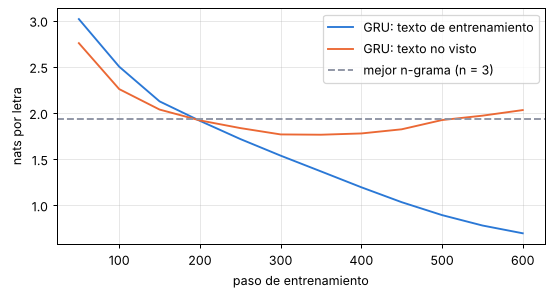

In [18]:
t0 = time.time()
gru = entrenar_lm(ENT, VOCAB, "gru", H=64, pasos=600, semilla=0, prueba=PRU)
print(f"entrenada en {time.time() - t0:.0f} s; mejor error en texto no visto {min(gru.hist['prueba']):.2f} en el paso {gru.mejor_paso}")
plt.figure(figsize=(7, 3.4))
plt.plot(gru.hist["paso"], gru.hist["entren"], color=AZUL, label="GRU: texto de entrenamiento")
plt.plot(gru.hist["paso"], gru.hist["prueba"], color=NARANJA, label="GRU: texto no visto")
plt.axhline(min(err), color=GRIS, ls="--", label=f"mejor n-grama (n = {MEJOR_N})")
plt.xlabel("paso de entrenamiento"); plt.ylabel("nats por letra"); plt.legend(); plt.grid(alpha=.3); plt.show()

Si se la frena a tiempo, la GRU predice el texto que no vio **mejor que el mejor n-grama**, con una tabla de tamaño fijo.
Si se la deja seguir, empieza a **memorizar** el corpus (que es chiquito) y el error en el texto no visto sube: el mismo
problema que el n-grama largo, por otro camino. Con millones de letras, una red así aprende a cerrar paréntesis y comillas
(Karpathy, 2015); con 5.400, no.

> ✍️ **Ejercicio:** cambiá `H=64` por `H=16` y por `H=128`. ¿Cuál memoriza antes?

## Paso 5 — De vuelta a la cueva: un agente con memoria

Volvemos al agente que solo siente bigotes. En cada paso recibe 8 números: los **4 bigotes** y su **última acción**
(*one-hot*). Comparamos dos redes con la misma entrada:

- **sin memoria**: una red común (MLP), que decide solo con lo que siente ahora;
- **con memoria**: una **GRU** de 32 estados, que decide con lo que siente y con su estado $h_t$.

**Cómo las entrenamos, dicho explícitamente.** No usamos RL acá: usamos **aprendizaje por imitación** (*behavior cloning*),
que es aprendizaje supervisado. Un experto que ve el mapa juega muchas partidas desde casillas al azar (con un 30 % de
acciones al azar, para que aparezcan situaciones fuera del camino ideal) y las redes aprenden a copiar **la acción del
experto** a partir de lo que siente el agente. La versión con RL existe y se llama DRQN (Hausknecht y Stone, 2015: DQN con
una capa recurrente), pero la probamos en la cueva chica y en dos minutos de CPU juega unas 200 partidas, todavía explorando,
y sale en 7 de cada 10: no converge en el tiempo de una clase.

Usamos la **cueva grande** (155 casillas, 13 lecturas), donde la diferencia se nota más.

155 casillas, 13 lecturas distintas, la más lejana a 46 pasos


datos: (2000, 60, 8) = 52989 pasos con su acción del experto


entrenadas en 26 s


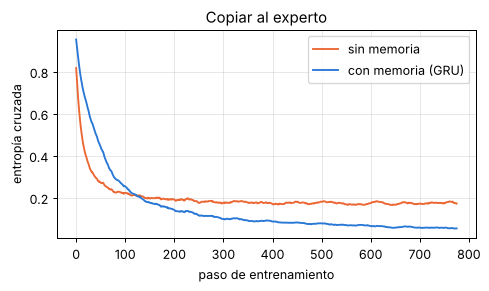

In [19]:
env_g = CaveEnv(CUEVA_GRANDE)
dist_g = distancias(env_g)
print(f"{env_g.nS} casillas, {len({bigotes(env_g, s) for s in range(env_g.nS)})} lecturas distintas, la más lejana a {dist_g.max()} pasos")
datos = datos_imitacion(env_g, dist_g, episodios=2000, T=60, eps=0.3, semilla=1)
print("datos:", tuple(datos[0].shape), "=", int(datos[3].sum()), "pasos con su acción del experto")

t0 = time.time()
sin = SinMemoria(32); h_sin = entrenar_imitacion(sin, datos, pasos=800)
con = ConMemoria(32); h_con = entrenar_imitacion(con, datos, pasos=800)
print(f"entrenadas en {time.time() - t0:.0f} s")
plt.figure(figsize=(6, 3)); plot_curva(plt.gca(), h_sin, NARANJA, "sin memoria"); plot_curva(plt.gca(), h_con, AZUL, "con memoria (GRU)")
plt.xlabel("paso de entrenamiento"); plt.ylabel("entropía cruzada"); plt.legend(); plt.grid(alpha=.3)
plt.title("Copiar al experto"); plt.show()

La GRU copia mucho mejor al experto. Pero lo que importa es si **sale**. Las ponemos a jugar desde cada una de las 154 casillas (máximo 200 pasos, siempre la acción más probable).

sin memoria : sale desde 88 de 154 casillas; cuando sale, 0.0 pasos de más que el óptimo
con memoria : sale desde 154 de 154 casillas; cuando sale, 2.2 pasos de más que el óptimo


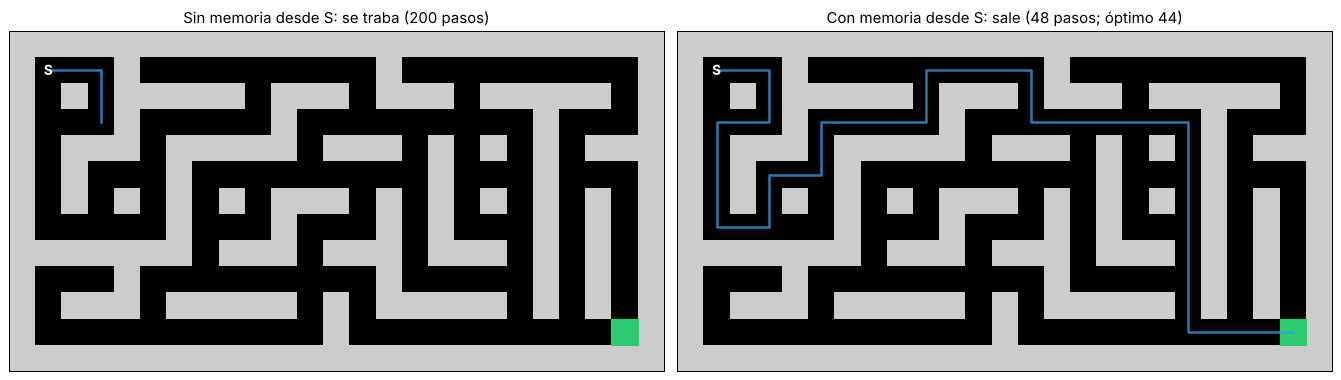

In [20]:
ev_sin, ev_con = evaluar(sin, env_g, dist_g), evaluar(con, env_g, dist_g)
for nombre, ev in [("sin memoria", ev_sin), ("con memoria", ev_con)]:
    print(f"{nombre:12s}: sale desde {round(ev['exito'] * ev['n'])} de {ev['n']} casillas; cuando sale, {ev['pasos_de_mas']:.1f} pasos de más que el óptimo")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
c_sin, _ = jugar(sin, env_g, env_g.start); c_con, _ = jugar(con, env_g, env_g.start)
env_g.plot(path=c_sin, ax=ax[0], title=f"Sin memoria desde S: {'sale' if c_sin[-1] == env_g.goal else 'se traba'} ({len(c_sin) - 1} pasos)")
env_g.plot(path=c_con, ax=ax[1], title=f"Con memoria desde S: {'sale' if c_con[-1] == env_g.goal else 'se traba'} ({len(c_con) - 1} pasos; óptimo {dist_g[env_g.start]})")
plt.tight_layout(); plt.show()

La red común se traba yendo y viniendo entre dos casillas que se sienten igual: con la misma lectura y la misma última
acción, toma siempre la misma decisión. **La última acción ya es memoria de un paso**, y en la cueva chica casi alcanza;
en la grande, no. La GRU sale desde todas.

### Dónde cree que está

El estado $h_t$ de la GRU son 32 números sin nombre. Para verlo entrenamos una **sonda** (*probe*): una capa lineal que,
a partir de $h_t$, adivina la casilla. No la usa el agente; es nuestra forma de leerle la mente. La dibujamos donde viven
las casillas: sobre la cueva.

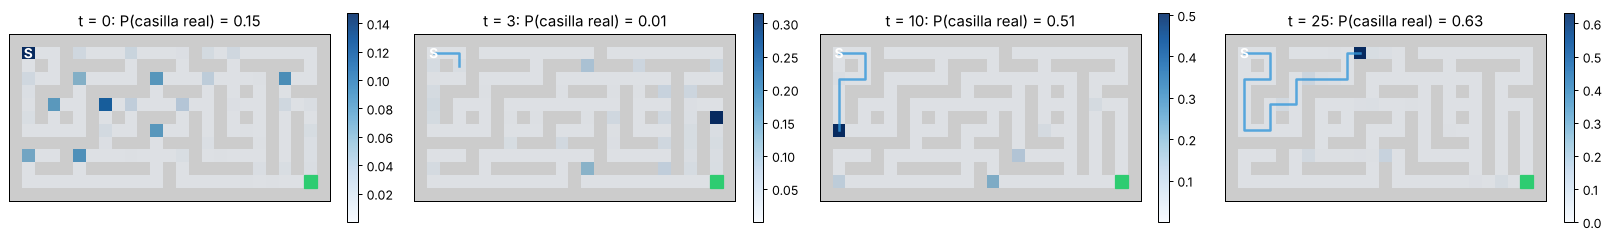

In [21]:
sonda = entrenar_sonda(con, datos, env_g)
camino, hs = jugar(con, env_g, env_g.start)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.4))
for k, t in enumerate([0, 3, 10, 25]):
    with torch.no_grad():
        p = torch.softmax(sonda(torch.tensor(hs[t])), -1).numpy()
    env_g.plot(values=p, ax=ax[k], path=camino[:t + 1], cmap="Blues", title=f"t = {t}: P(casilla real) = {p[camino[t]]:.2f}")
plt.tight_layout(); plt.show()

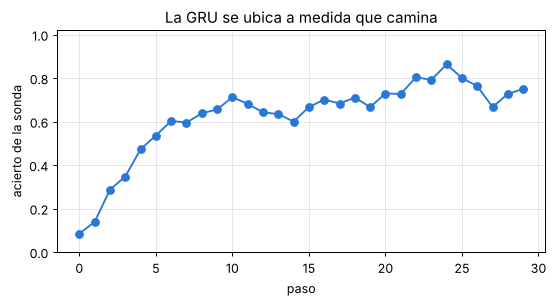

acierto en t=0: 0.08   en t=10: 0.71


In [22]:
# acierto de la sonda según el paso, promediado sobre todas las salidas
aciertos = np.zeros(30); cuantos = np.zeros(30)
for s0 in range(env_g.nS):
    if s0 == env_g.goal: continue
    camino, hs = jugar(con, env_g, s0, T=30)
    with torch.no_grad():
        pred = sonda(torch.tensor(np.array(hs))).argmax(-1).numpy()
    for t, s in enumerate(camino[:len(pred)]):
        aciertos[t] += pred[t] == s; cuantos[t] += 1
plt.figure(figsize=(7, 3.2)); plt.plot(aciertos / np.maximum(cuantos, 1), "o-", color=AZUL)
plt.xlabel("paso"); plt.ylabel("acierto de la sonda"); plt.ylim(0, 1.02); plt.grid(alpha=.3)
plt.title("La GRU se ubica a medida que camina"); plt.show()
print(f"acierto en t=0: {aciertos[0]/cuantos[0]:.2f}   en t=10: {aciertos[10]/max(cuantos[10],1):.2f}")

Al principio la sonda acierta poco: con una sola lectura, nadie puede saber dónde está. Y a veces se equivoca con
confianza (en la figura de arriba, en t = 3 apuesta por un pasillo del otro lado que se siente igual); unos pasos después se
corrige. A medida que camina, el estado
acumula la historia y la sonda la encuentra: **la red aprendió sola algo parecido al estado de creencia del Paso 2**,
sin que nadie le diera el mapa.

> ✍️ **Ejercicio:** repetí el Paso 5 con la cueva chica (`env_g = CaveEnv()`). ¿La red común también se traba?
> ¿Por qué la última acción alcanza más en una cueva que en la otra?

## Paso 6 — El puente: un modelo de lenguaje es esto, a escala

Lo que hicimos hoy dos veces es lo mismo: **leer un camino de a un paso y llevar un resumen**. En la cueva el resumen sirve
para decidir la acción; en el texto, para predecir la letra que sigue. Un modelo de lenguaje como Qwen2.5-0.5B, el que van a
usar los agentes de las clases 10 y 11, hace la segunda tarea con palabras en vez de letras y con mucho más texto.

In [23]:
tamanos = {
    "n-grama n=8 (contextos × letras)": len(tabla_ngramas(CORPUS, 8)) * len(VOCAB),
    "RNN de letras (Paso 4)": sum(p.numel() for p in elman.parameters()),
    "agente GRU (Paso 5)": sum(p.numel() for p in con.parameters()),
    "Qwen2.5-0.5B (clases 10 y 11)": 494_000_000,
}
for k, v in tamanos.items():
    print(f"{k:34s} {v:>13,}".replace(",", "."))

n-grama n=8 (contextos × letras)         147.516
RNN de letras (Paso 4)                     3.558
agente GRU (Paso 5)                        4.164
Qwen2.5-0.5B (clases 10 y 11)        494.000.000


El salto de escala no es lo único que cambia. Un **transformer**, en una frase: en vez de recorrer el camino pasando el estado
de mano en mano, en cada paso **mira a la vez todas las letras anteriores y elige a cuáles atender**. Así no depende de que
el gradiente sobreviva cien pasos, a cambio de mirar todo cada vez.

## Preguntas para pensar

1. En el Paso 2 calculamos la creencia exacta porque conocíamos el mapa. Si el piso fuera resbaloso (clase 3), ¿la creencia
   seguiría siendo un conjunto, o haría falta una probabilidad por casilla?
2. La red común del Paso 5 se traba yendo y viniendo. ¿Le alcanzaría con elegir la acción al azar según sus probabilidades,
   en vez de la más probable? ¿Qué perdería?
3. Un n-grama y una RNN predicen la próxima letra. ¿Qué guarda cada uno del pasado? ¿Cuál se parece más a tu forma de leer?

## Próxima clase

Clase 8: **aplicaciones**. Llevamos lo aprendido a problemas reales: marketing, un tutor, un robot. Y en las clases 10 y 11 el
modelo de lenguaje de hoy, a escala, se vuelve un agente: su acción es el próximo texto.